# EDA датасета товаров Золотого Яблока

In [37]:
# Введение

Датасет собирал с сайта goldapple.ru, скраппингом, муторно и долго
Там 11992 товара и 20 столбцов: цены, рейтинг, отзывы, категории, тип кожи, объем, страна и тд

Задача ЕДАшки - оценить качество данных, структуру, пропуски, дубликаты, выбросы, мусор

План:
1. Загрузка структура
2. Целостность , полные ли данные
3. Числовые признаки, разбор
4. Выбросы
5. Категориии признаки
6. Семантический анализ текстовых полей
7. Метрики качества
8. Выводы

In [38]:
import os
import sys

import pandas as pd
import plotly.express as px
import plotly.io as pio

# как выяснилось, github не умеет в интерактивный плотли, а я очень сильно его люблю, поэтому графики сохраняем картинками
pio.renderers.default = "png"
pio.templates.default = "plotly_white"

In [39]:
# пути относительно корня репо
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append("src")
from data_loader import load_data, fix_types

# 1. Загрузка и структура

Сырой csv и отдельно версию с приведенными типами (fix_types из третьей домашки). Сырой нужен чтобы посмотреть как она есть

In [40]:
raw = load_data()
df = fix_types(raw)
print(raw.shape)
raw.head()

(11992, 20)


,item_id,name,brand,product_type,price_actual,price_regular,rating,reviews_count,in_stock,category_main,category_sub,target_area,purpose,skin_type,target_audience,volume,application_time,active_ingredient,country,url
0,10041200003,Йогурт,STYX,крем для лица,3149,3620,4.5,8.0,True,уход для лица,увлажнение и питание,лицо,"увлажнение, питание",для всех типов кожи,универсально,50 мл,в любое время,NaN,страна происхождения Австралия,https://goldapple.ru/10041200003-jogurt
1,10041200005,KRAUTERGARTEN,STYX,КРЕМ ДЛЯ НОРМАЛЬНОЙ КОЖИ,3149,3620,4.8,4.0,True,уход для лица,увлажнение и питание,лицо,"увлажнение, питание",для нормальной кожи,универсально,50 мл,в любое время,NaN,страна происхождения Австралия,https://goldapple.ru/10041200005-krautergarten
2,10041200006,Жожоба,STYX,Крем для лица,3329,4690,4.9,30.0,True,уход для лица,антивозрастной уход,лицо,против признаков старения,для всех типов кожи,для женщин,50 мл,в любое время,NaN,страна происхождения Австралия,https://goldapple.ru/10041200006-zhazhoba
3,10240100022,ointment strawberry,Pure Paw Paw,Восстанавливающий бальзам,301,520,4.9,470.0,True,губы,уход для губ,"губы, ноги, руки","восстановление, увлажнение, питание",для всех типов кожи,NaN,NaN,NaN,NaN,страна происхождения Австралия,https://goldapple.ru/10240100022-s-aromatom-kl...
4,10240100025,ointment grape,Pure Paw Paw,Восстанавливающий бальзам,379,520,4.7,136.0,True,губы,уход для губ,"губы, руки, ноги","восстановление, увлажнение, питание",для всех типов кожи,NaN,NaN,NaN,NaN,страна происхождения Австралия,https://goldapple.ru/10240100025-s-aromatom-vi...


In [41]:
types = pd.DataFrame({"было": raw.dtypes.astype(str), "стало": df.dtypes.astype(str)})
types

,было,стало
item_id,int64,string
name,object,string
brand,object,category
product_type,object,string
price_actual,int64,int32
price_regular,int64,int32
rating,float64,float32
reviews_count,float64,Int32
in_stock,bool,bool
category_main,object,category


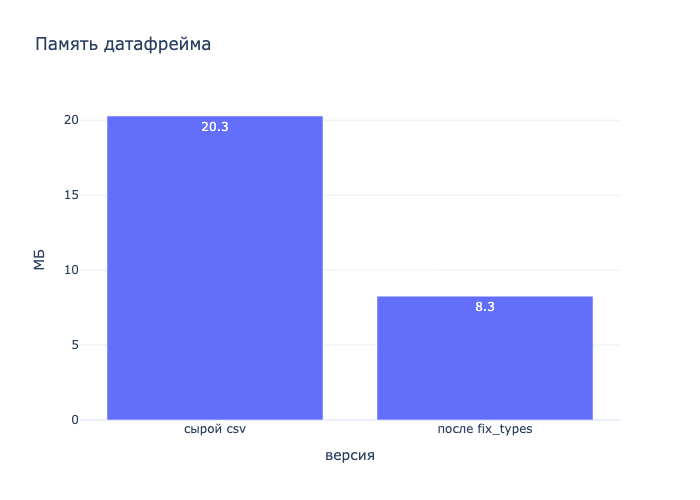

In [42]:
mem = pd.DataFrame({
    "версия": ["сырой csv", "после fix_types"],
      "МБ": [raw.memory_usage(deep=True).sum() / 1e6, df.memory_usage(deep=True).sum() / 1e6],
})
fig = px.bar(mem, x="версия", y="МБ", text_auto=".1f", title="Память датафрейма")
fig.show()

Почти все столбцы в сыром виде object, числовые только цены, рейтинг и отзывы по сути

После приведения типов датафрейм весит в ~2.5 раза меньше

Сразу видно что name это не полное название, а скорее линейка ("CLEANSING", "Sensibio"), бренд вынесен отдельно

# 2. Целостность, полнота

Пропуски

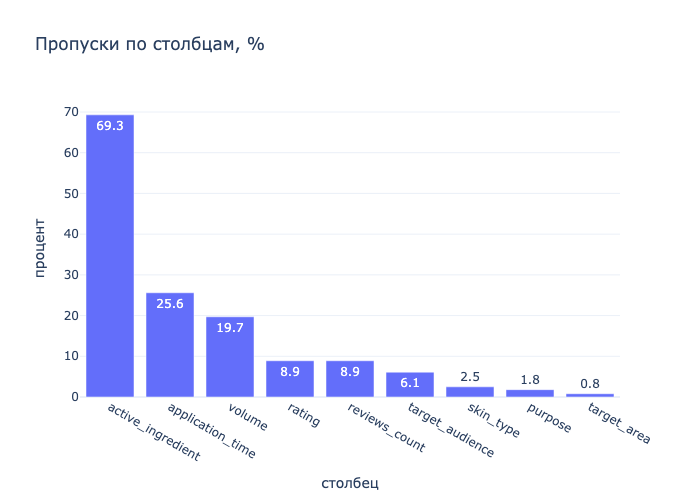

In [43]:
na = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
na = na[na > 0].reset_index()
na.columns = ["столбец", "процент"]
fig = px.bar(na, x="столбец", y="процент", text_auto=True, title="Пропуски по столбцам, %")
fig.show()

- active_ingredient пустой у 69% товаров - на сайте его просто не у всех указывают. Для анализа почти бесполезен
- application_time 26% и volume 20% - заметно, но жить можно
- rating и reviews_count по 8.9%. Проверим что это одни и те же строки (товар без отзывов = нет рейтинга)

In [44]:
print("пропуски rating и reviews_count совпадают:", (raw["rating"].isna() == raw["reviews_count"].isna()).all())
print("минимум отзывов там где они есть:", raw["reviews_count"].min())

пропуски rating и reviews_count совпадают: True
минимум отзывов там где они есть: 1.0


Совпадают полностью, и нулей в отзывах нет

# Дубликаты

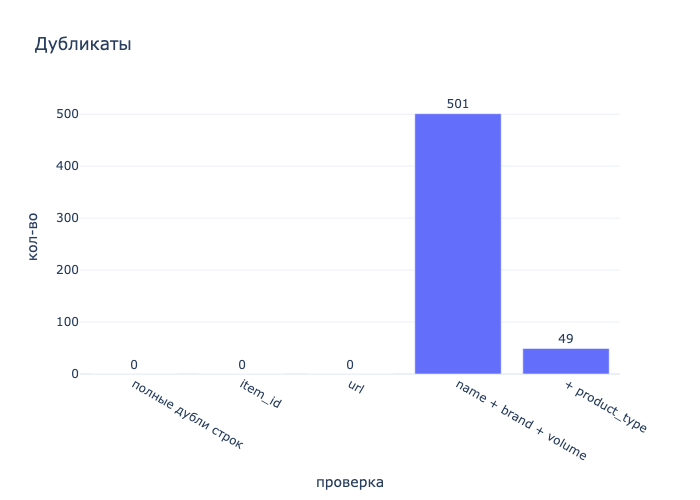

In [45]:
dups = pd.DataFrame({
    "проверка": ["полные дубли строк", "item_id", "url", "name + brand + volume", "+ product_type"],
    "кол-во": [
        raw.duplicated().sum(),
         raw["item_id"].duplicated().sum(),
        raw["url"].duplicated().sum(),
        raw.duplicated(["name", "brand", "volume"]).sum(),
        raw.duplicated(["name", "brand", "volume", "product_type"]).sum(),
    ],
})
# нули внутри столбика не видно, поэтому подписи снаружи
fig = px.bar(dups, x="проверка", y="кол-во", text_auto=True, title="Дубликаты")
fig.update_traces(textposition="outside", cliponaxis=False)
fig.show()

In [46]:
key = ["name", "brand", "volume", "product_type"]
raw[raw.duplicated(key, keep=False)].sort_values(key)[key + ["skin_type", "price_actual", "item_id"]].head(10)

,name,brand,volume,product_type,skin_type,price_actual,item_id
9472,100% Collagen,Dizao,NaN,ГИДРОГЕЛЕВЫЕ Патчи для глаз,"для всех типов кожи, для чувствительной кожи",563,19000448270
9473,100% Collagen,Dizao,NaN,ГИДРОГЕЛЕВЫЕ Патчи для глаз,"для всех типов кожи, для чувствительной кожи",113,19000448271
7746,All-day Airy Mineral,"Dear, klairs",NaN,Крем для лица SPF50+ PA++++,для чувствительной кожи,747,19000357230
7747,All-day Airy Mineral,"Dear, klairs",NaN,Крем для лица SPF50+ PA++++,для чувствительной кожи,1600,19000357232
3357,BLUR SUN SECURE,SVR,50 мл,Солнцезащитный крем-мусс для лица SPF 50+,для всех типов кожи,1792,19000135862
5768,BLUR SUN SECURE,SVR,50 мл,Солнцезащитный крем-мусс для лица SPF 50+,для всех типов кожи,1971,19000252741
844,Bad Doll,Belor Design,NaN,Бальзам-тинт для губ,для всех типов кожи,170,19000022369
4462,Bad Doll,Belor Design,NaN,Бальзам-тинт для губ,для всех типов кожи,166,19000185853
7808,Botox effect,Name Skin Care,NaN,Альгинатная моделирующая маска для лица,для всех типов кожи,171,19000360775
7809,Botox effect,Name Skin Care,NaN,Альгинатная моделирующая маска для лица,для всех типов кожи,770,19000360776


По id и url дублей нет. По названию + бренду + объему совпадает 501 товар, но это в основном разные продукты одной линейки (у Round Lab "1025 DOKDO" это и диски, и салфетки), name тут не уникальное название

# 3. Числовые признаки

Числовых столбцов не много: две цены, рейтинг, отзывы и объем (после чистки)

In [47]:
num_cols = ["price_actual", "price_regular", "rating", "reviews_count", "volume"]
stats = df[num_cols].describe().T
stats["median"] = df[num_cols].median()
stats["skew"] = df[num_cols].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew
price_actual,11992.0,2908.042612,5755.067762,26.0,499.0,1161.0,2957.0,110107.0,1161.0,6.58
price_regular,11992.0,3678.610407,6871.486035,30.0,735.0,1691.0,3863.0,146810.0,1691.0,6.97
rating,10924.0,4.487129,0.516715,1.0,4.3,4.6,4.8,5.0,4.6,-2.61
reviews_count,10924.0,113.937111,474.226774,1.0,6.0,21.0,76.0,24697.0,21.0,21.26
volume,9634.0,90.071037,87.407784,1.0,30.0,50.0,125.0,1000.0,50.0,2.4


У цен и отзывов среднее сильно больше медианы и большая асимметрия (skew) - длинный хвост вправо. Поэтому дальше смотрю на них интервалами, обычная гистограмма будет одним столбиком у нуля.

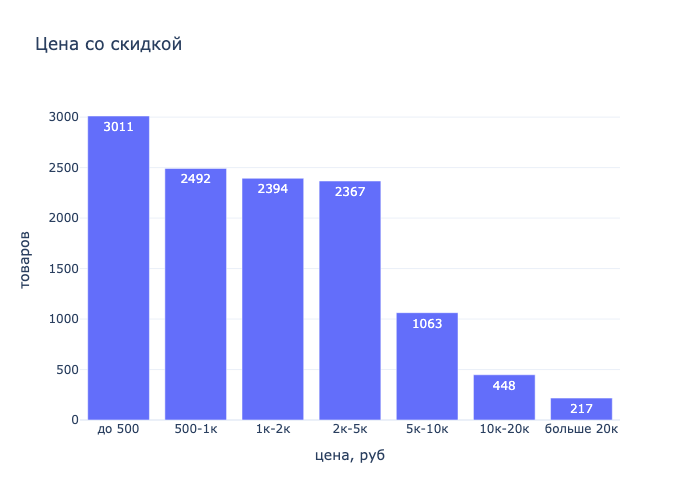

In [48]:
bins = [0, 500, 1000, 2000, 5000, 10000, 20000, 200000]
labels = ["до 500", "500-1к", "1к-2к", "2к-5к", "5к-10к", "10к-20к", "больше 20к"]
price_groups = pd.cut(df["price_actual"], bins=bins, labels=labels).value_counts(sort=False).reset_index()
price_groups.columns = ["цена, руб", "товаров"]
fig = px.bar(price_groups, x="цена, руб", y="товаров", text_auto=True, title="Цена со скидкой")
fig.show()

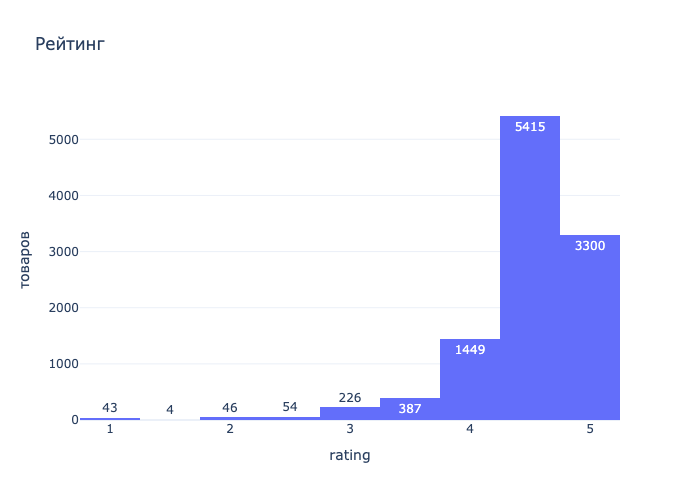

In [49]:
fig = px.histogram(df, x="rating", nbins=20, text_auto=True, title="Рейтинг")
fig.update_layout(yaxis_title="товаров")
fig.show()

Рейтинг сильно смещен к высоким значениям, медиана 4.6, у 7361 из 10924 товаров рейтинг 4.5 и выше

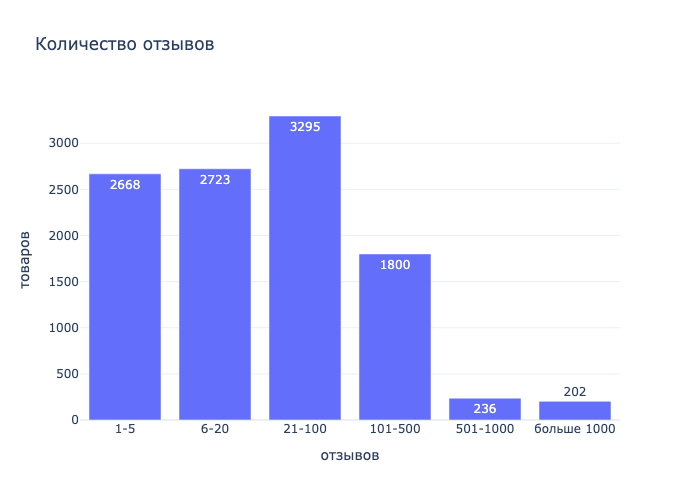

In [50]:
bins = [0, 5, 20, 100, 500, 1000, 30000]
labels = ["1-5", "6-20", "21-100", "101-500", "501-1000", "больше 1000"]
rev_groups = pd.cut(df["reviews_count"], bins=bins, labels=labels).value_counts(sort=False).reset_index()

rev_groups.columns = ["отзывов", "товаров"]
fig = px.bar(rev_groups, x="отзывов", y="товаров", text_auto=True, title="Количество отзывов")
fig.show()

У большинства товаров меньше 20 отзывов, значит их рейтинг не очень надежный - пара оценок и уже 5.0 или 1.0

# Выбросы и аномалии

Выбросы по IQR
Считаю выбросом все что дальше 1.5 от квартилей

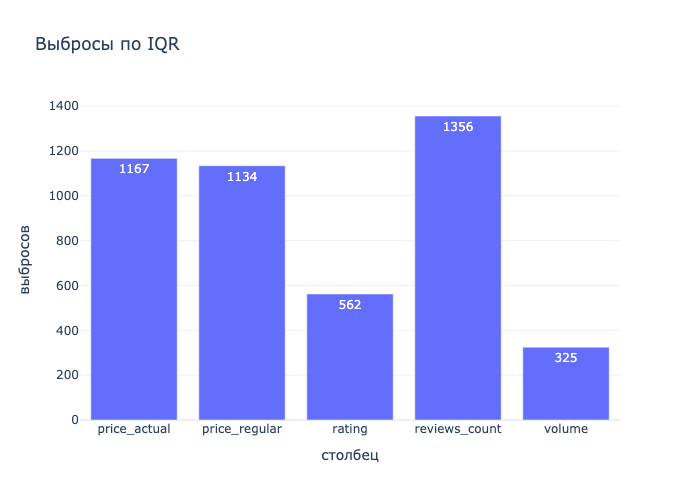

In [52]:
def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({"столбец": num_cols, "выбросов": [iqr_outliers(df[c].dropna()) for c in num_cols]})
fig = px.bar(out, x="столбец", y="выбросов", text_auto=True, title="Выбросы по IQR")
fig.show()

In [ ]:
df.nlargest(5, "price_actual")[["name", "brand", "category_main", "price_actual", "volume"]]

In [ ]:
df.nlargest(5, "reviews_count")[["name", "brand", "reviews_count", "rating"]]

Выбросов по IQR много (у цены больше тысячи), но если посмотреть глазами - не ошибки. Самые дорогие погуглив это люксовые бренды (Sisley, Clé de Peau, 3LAB, Valmont) за 90-110 тыс, самые популярные -  типо "хиты"/массмаркет вроде Bioderma Sensibio. То есть хвосты реальные, удалять их не надо, просто учитывать что распределения не нормальные.

Логические проверки

In [ ]:
discount = ((1 - df["price_actual"] / df["price_regular"]) * 100).round()
checks = pd.DataFrame({
    "проверка": [
        "цена со скидкой > обычной",
        "скидка 0%",
        "скидка 70% и больше",
        "рейтинг вне 1-5",
        "рейтинг <= 2 при 3 отзывах и меньше",
        "нет в наличии",
    ],
    "кол-во": [
        (df["price_actual"] > df["price_regular"]).sum(),
        (discount == 0).sum(),
        (discount >= 70).sum(),
        ((df["rating"] < 1) | (df["rating"] > 5)).sum(),
        ((df["rating"] <= 2) & (df["reviews_count"] <= 3)).sum(),
        (~df["in_stock"]).sum(),
    ],
})
fig = px.bar(checks, x="кол-во", y="проверка", orientation="h", text_auto=True, title="Логические проверки")
fig.update_traces(textposition="outside", cliponaxis=False)
fig.show()

In [ ]:
fig = px.histogram(discount, nbins=16, text_auto=True, title="Размер скидки, %")
fig.update_layout(showlegend=False, xaxis_title="скидка, %", yaxis_title="товаров")
fig.show()

- Цен где скидка больше обычной цены нет, рейтинг всегда в 1-5 - тут норма
- У 2760 товаров скидки нет (цены равны), у остальных скидка в основном 10-40%. Максимум - 80
- Почти все низкие рейтинги у товаров с 1-3 отзывами - это просто маленькая выборка.
- 620 товаров нет в наличии, но цена у них все равно есть

Объем

In [ ]:
fig = px.bar(df["volume"].value_counts().head(10).reset_index(), x="volume", y="count", text_auto=True,
             title="Топ-10 значений объема, мл")
fig.update_xaxes(type="category")
fig.show()

In [ ]:
# что было в объеме кроме "... мл"
raw.loc[raw["volume"].notna() & ~raw["volume"].str.contains("мл", na=False), ["name", "volume"]]

Объемы стандартные: 30, 50, 100, 150, 200 мл. Но в сыром поле нашлись странные значения: "200" без единиц и "50 л" (крем на 50 литров явно опечатка, скорее всего 50 мл). При чистке в fix_types "л" просто отрезается, так что 50 л случайно превратилось в 50 мл - повезло, но надо переводить нормально)

# Категориальные признаки

In [ ]:
cat_cols = ["brand", "product_type", "category_main", "category_sub", "target_area", "skin_type",
            "target_audience", "application_time", "country", "purpose", "active_ingredient"]
nun = raw[cat_cols].nunique().sort_values().reset_index()
nun.columns = ["столбец", "уникальных"]
fig = px.bar(nun, x="уникальных", y="столбец", orientation="h", text_auto=True,
             title="Уникальных значений в сыром csv")
fig.show()

- product_type, purpose, active_ingredient - по сути свободный текст, тысячи вариантов
- country 1738 уникальных - стран столько не бывает, тут явно мусор/что-то не так

In [ ]:
cat = df["category_main"].value_counts().reset_index()
fig = px.bar(cat, x="count", y="category_main", orientation="h", text="count", title="Основная категория")
fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(range=[0, 12500])
fig.show()

Датасет несбалансирован: 10840 из 11992 это уход для лица, я собирал в основном этот раздел. Остальные категории по 1-400 товаров, а "аксессуары", "уход для волос", "для мужчин", "лицо" вообще по одному. Причем "лицо" и "уход" похожи на дубли "уход для лица" с другим названием

In [ ]:
fig = px.bar(df["target_audience"].value_counts().reset_index(), x="target_audience", y="count",
             text_auto=True, title="Для кого")
fig.show()

"универсально" и "унисекс" по смыслу одно и то же, плюс есть одна запись "для женщин, универсально". Это стоит объединить при чистке

# Семантический анализ текстовых полей

Смотрю на смысл а не написание

Страна

In [ ]:
raw["country"].sample(5, random_state=2).tolist()

В поле кроме страны лежит "страна происхождения", а иногда еще изготовитель с полным адресом. fix_types это уже отрезает.

In [ ]:
fig = px.bar(df["country"].value_counts().head(10).reset_index(), x="count", y="country", orientation="h",
             text_auto=True, title="Топ-10 стран после чистки")
fig.update_yaxes(autorange="reversed")
fig.show()

После чистки остается 43 страны. Больше всего Кореи и России. Есть еще длинное "Китай (Китайская Народная Республика)" - формулировки на сайте не единообразные, к сожалению

Тип кожи и зона применения

В этих полях часто несколько значений через запятую, и порядок разный: "лицо, шея и декольте" и "шея и декольте, лицо" это одно и то же. Разобью на части и отсортирую

In [ ]:
def normalize(s):
    parts = s.str.lower().str.split(",")
    return parts.apply(lambda x: ", ".join(sorted(p.strip() for p in x)) if isinstance(x, list) else None)

def single_values(s):
    return s.str.lower().str.split(",").explode().str.strip().nunique()

sem = []
for col in ["country", "skin_type", "target_area"]:
    sem.append([col, "как есть", raw[col].nunique()])
    if col == "country":
        sem.append([col, "после чистки", df[col].nunique()])
    else:
        sem.append([col, "без учета порядка", normalize(raw[col]).nunique()])
        sem.append([col, "отдельных значений", single_values(raw[col])])
sem = pd.DataFrame(sem, columns=["столбец", "вариант", "уникальных"])
fig = px.bar(sem, x="столбец", y="уникальных", color="вариант", barmode="group", text_auto=True,
             title="Сколько реально разных значений")
fig.update_traces(textposition="outside", cliponaxis=False)
fig.show()

In [ ]:
skin = raw["skin_type"].str.split(",").explode().str.strip().value_counts().reset_index()
fig = px.bar(skin, x="count", y="skin_type", orientation="h", text_auto=True, title="Отдельные типы кожи")
fig.update_yaxes(autorange="reversed")
fig.show()

- country: из 1738 в 43, почти все разнообразие было мусором
- skin_type: 165 комбинаций, без учета порядка 98, а отдельнчх типов всего 10. Лучше хранить как набор флагов, а не одной строкой
- target_area: то же самое, 74 -> 48 -> 16 отдельных зон

"для всех типов кожи" у 8750 товаров, причем иногда вместе с конкретным типом - это логически немного противоречиво

# Метрики качества

Свожу все в несколько чисел:
- полнота - доля непустых ячеек
- уникальность - доля уникальных item_id
- валидность - доля строк, прошедших логические проверки (цена со скидкой <= обычной, рейтинг в 1-5, объем от 1 до 1000 мл)
- консистентность - доля строк без возможного дубля по name + brand + volume + product_type

In [ ]:
valid = (
    (df["price_actual"] <= df["price_regular"])
    & (df["rating"].between(1, 5) | df["rating"].isna())
    & (df["volume"].between(1, 1000) | df["volume"].isna())
)
metrics = pd.DataFrame({
    "метрика": ["полнота", "полнота без active_ingredient", "уникальность id", "валидность", "консистентность"],
    "процент": [
        raw.notna().mean().mean() * 100,
        raw.drop(columns="active_ingredient").notna().mean().mean() * 100,
        raw["item_id"].nunique() / len(raw) * 100,
        valid.mean() * 100,
        (~raw.duplicated(["name", "brand", "volume", "product_type"])).mean() * 100,
    ],
}).round(1)
fig = px.bar(metrics, x="метрика", y="процент", text_auto=True, title="Метрики качества, %")
fig.update_yaxes(range=[0, 105])
fig.show()

# Выводы

Что хорошо:
- нет дублей по id и url
- цены и рейтинг логически корректные, ошибок вроде "скидочная цена больше обычной" нет
- пропуски в rating и reviews_count не случайные, это товары без отзывов
- выбросы в ценах и отзывах реальные (люкс бренды и "хиты"/массмаркет), а не ошибки

Проблемы:
1. active_ingredient пустой у 69%, можно дроппнуть
2. сильный перекос в сторону ухода для лица (но я изначально так датасет и подбирал под задачу)
3. мусор в country (адреса изготовителей) - поправил, стало 43 страны
4. skin_type и target_area - списки в строке с разным порядком, надо раскладывать на флаги
5. синонимы в категориях: "универсально" /"унисекс", "уход для лица"/ "лицо" / "уход"
6. в объеме попадаются значения без единиц и в литрах ("50 л"), чистку объема надо поправлять
7. 49 возможных дублей (одинаковые name, brand, volume и product_type), по имеющимся полям не отличить вариант товара от повтора
8. у большинства товаров меньше 20 отзывов, рейтинг у них шумный

В целом данные довольно адекватные по числовой части, основная проблема в текстовых и категориальных полях